# Object-centric project mining: a guided tour

Issue trackers record how a software release unfolds, but not its project network: which tasks
had to wait for which, which ones determined the end of the release, and how much each task
could have been delayed. Object-centric project mining recovers this network from an
object-centric event log (OCEL) of the tracker and shows it as a **PERT chart** with typed
precedence relations.

This notebook shows the technique on the running example of the paper and on a real release,
and compares it with object-centric process mining on the same data:

1. The running example as an OCEL
2. Object-centric process mining: the directly-follows graph
3. Object-centric project mining: the project network as a PERT chart
4. A real release: Apache Mesos 1.0.0
5. What project mining adds

It needs no data download and no LLM key. The textual evidence comes from the cached LLM
answers in `results/e3/`.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

sys.path.insert(0, str(Path("..") / "code"))
import e3_llm
import running_example as rx
import views
from mining import load_ocel, mine

pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "font.size": 8})

ModuleNotFoundError: No module named 'matplotlib'

## 1 The running example as an OCEL

Release $R$ of the running example (Table 1 of the paper) has six tasks. $A$, $B$, and $C$ fix
incompatibilities with a new version of the programming language, $D$ upgrades the test
framework, $E$ switches the continuous integration (CI) to the new version, and $F$ fixes a
regression introduced by $A$. $A$–$E$ belong to epic $X$. `running_example.build()` writes the
tracker records as an OCEL in the relational OCEL 2.0 format. The tracker keys `PRJ-1` to
`PRJ-7` are shown as the letters of the paper, and times as days since the start of epic $X$.

In [2]:
rx.build()
L = load_ocel(rx.DB)
TASKS, LABEL = list(rx.ISSUES), rx.LETTER          # tracker keys and the letters of the paper
TITLE = L.issues["title"].to_dict()

events = views.event_table(L, TASKS, LABEL, t0=rx.T0)
events["detail"] = events["detail"].replace(LABEL, regex=True)
events

,day,activity,objects,detail
0,0.0,In Progress,E (issue),
1,1.0,In Progress,B (issue),
2,2.0,In Progress,A (issue),
3,2.0,In Progress,C (issue),
4,6.0,In Progress,D (issue),
5,7.0,add link,"A (source), E (target)",blocks
6,7.0,add link,"B (source), E (target)",blocks
7,7.0,add link,"C (source), E (target)",blocks
8,8.0,add link,"A (source), D (target)",blocks
9,9.0,comment,D (issue),"To test this with the new version, we need all issues of epic X to be applied."


Each event is related to all objects it involves. Adding link $l_1$ on day 7, for instance, is
one event of both $A$ (source) and $E$ (target). An event log with one case per issue would
have to duplicate this event or drop one of the two issues. The links, the epic, and the release
are also kept as relations between objects:

In [3]:
L.o2o.replace(LABEL).rename(columns=lambda c: c.removeprefix("ocel_"))

,source_id,target_id,qualifier
0,A,release:R,fix version
1,B,release:R,fix version
2,C,release:R,fix version
3,D,release:R,fix version
4,E,release:R,fix version
5,F,release:R,fix version
6,A,X,part of epic
7,B,X,part of epic
8,C,X,part of epic
9,D,X,part of epic


## 2 Object-centric process mining: the directly-follows graph

Process discovery summarizes how the objects of one type move through activities. The
object-centric directly-follows graph (Def. 2 of the paper) counts how often one activity
directly follows another in the trace of an issue. Activities are the event types, and status
changes are named after the new status. Arcs carry their frequency, and ↻ counts repetitions of
an activity.

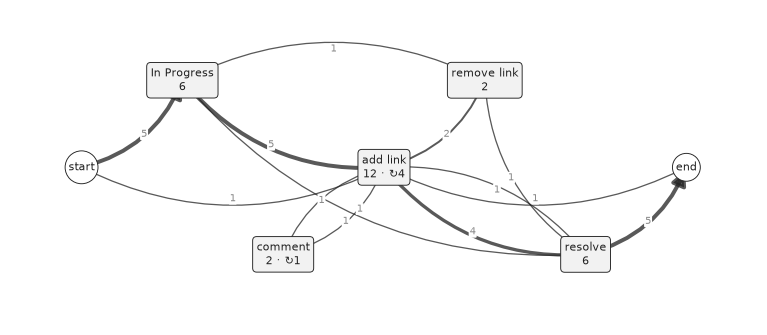

In [4]:
nodes, arcs = views.ocdfg(L, TASKS)
views.plot_dfg(nodes, arcs);

The graph shows the workflow of the issues: they are set in progress, linked, commented on,
and resolved. It does not show which issue waited for which, because activities abstract from
the individual objects. Proposition 1 of the paper makes this precise. Exchanging the identities
of two tasks, here $A$ and $E$, leaves the graph unchanged, whereas the dependencies change
(declared links only):

In [5]:
swapped = views.swap_objects(L, rx.A, rx.E)
precedences = lambda log: sorted((LABEL[i], LABEL[j]) for i, j in mine(log, "release:R", durations=False).edges)

print("same directly-follows graph:", views.ocdfg(swapped, TASKS)[1].equals(arcs))
print("precedences of the original log:", precedences(L))
print("precedences after the swap:     ", precedences(swapped))

same directly-follows graph: True
precedences of the original log: [('A', 'D'), ('A', 'E'), ('A', 'F'), ('B', 'E'), ('C', 'E')]
precedences after the swap:      [('B', 'A'), ('C', 'A'), ('E', 'A'), ('E', 'D'), ('E', 'F')]


## 3 Object-centric project mining: the project network as a PERT chart

Project mining asks which tasks of a project had to wait for which. `mine` derives the project
network of a project object, here release $R$, in Steps 2–5 of the paper:

* **Tasks and lifecycles.** The tasks are the issues of the release. A task starts with its
  first transition into an in-progress status and finishes with its resolution.
* **Evidence.** Declared links (E1), relations between objects such as a shared epic (E2), and
  statements in titles, descriptions, and comments (E3). E3 comes from an LLM that must quote
  the sentence that supports each dependency.
* **Typed precedence.** A precedence keeps a stated type if the observed times satisfy it.
  Untyped links such as *blocks* become finish-to-start (FS) if the successor started after the
  predecessor finished, and finish-to-finish (FF) otherwise. Precedences that contradict the
  observed times are dropped, and a removed link counts against a dependency.
* **Durations and critical path.** With durations estimated from earlier tasks, or with the
  observed durations after the fact, the network yields the critical path and the slack of each
  task.

In [6]:
e3 = e3_llm.as_evidence(e3_llm.load("EXAMPLE"))
net = mine(L, "release:R", e3=e3)
views.precedence_table(net, LABEL)

,predecessor,successor,type,stated type,support,evidence,structural relations,quote
0,A,E,FF,,1.25,declared,same epic,
1,B,E,FF,,1.25,declared,same epic,
2,C,E,FF,,1.25,declared,same epic,
3,A,D,FF,,1.25,declared,same epic,
4,A,F,FS,,1.00,declared,,
5,B,D,FF,FS,1.16,text only (hidden),same epic,"[2026-01-14] To test this with the new version, we need all issues of epic PRJ-7 to be applied."
6,C,D,FF,FS,0.96,text only (hidden),same epic,"[2026-01-14] To test this with the new version, we need all issues of epic PRJ-7 to be applied."


$A$, $B$, and $C$ were declared as blockers of $E$, but $E$ started before they finished, so
the precedences hold as FF, not FS. $F$ started only after $A$ was resolved, so $A \prec F$ is
FS. No link declares $B \prec D$ and $C \prec D$: they are **hidden** dependencies, stated only
in comment $c_1$ of $D$, which the LLM quoted. Two candidates were discarded:

In [7]:
views.dropped_table(net, LABEL)

,predecessor,successor,reason,type,support,evidence
0,F,D,support not above θ,FF,-1.00,removed link
1,E,D,contradicts the observed times,FF,1.09,text only (hidden)


$F \prec D$ was declared and later removed, which counts as negative evidence. $E \prec D$
follows from $c_1$ ("all issues of epic $X$"), but $E$ finished after $D$, so it did not hold.

### The PERT chart

Each box is a task with its observed duration and its realized slack: how much later it could
have finished without delaying the end of the release. The critical task is dark. Arrows are
labelled with the type of the precedence. Dashed arrows are hidden dependencies.

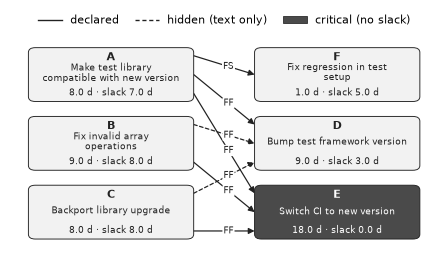

In [8]:
views.plot_pert(net, labels=LABEL, titles=TITLE);

The Gantt chart places the same network on the time axis. Arrows connect the ends that a
precedence constrains: the finish of the predecessor with the start (FS) or the finish (FF) of
the successor.

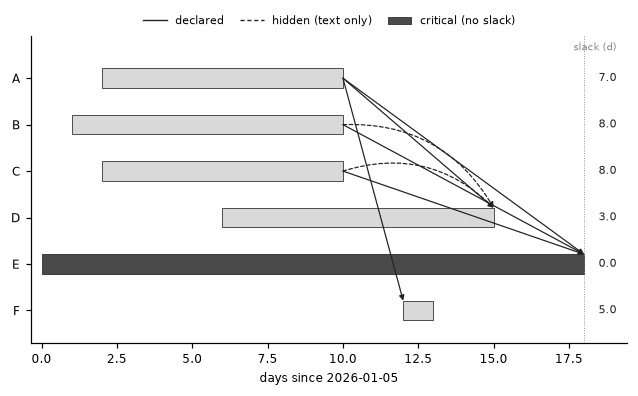

In [9]:
views.plot_gantt(net, labels=LABEL, order=TASKS);

$E$ is the only critical task: the switch of the CI marks the end of the release. Although $A$,
$B$, and $C$ were declared as blockers, they finished eight days before $E$ and could have been
delayed by seven to eight days. $D$ had three days of slack, $F$ five.

## 4 A real release: Apache Mesos 1.0.0

The sample OCEL in `data-sample/` holds the records of the issues of release 1.0.0 of the
Apache Mesos tracker, derived from the TAWOS dataset, and the earlier issues that duration
estimation needs. Abandoned issues are not tasks, and sub-tasks are aggregated into their
parents.

In [10]:
SAMPLE = Path("..") / "data-sample" / "MESOS-1.0.0.sqlite"
objects, event_types, multi = views.ocel_overview(SAMPLE)
print(f"{multi:.0%} of the events involve at least two objects other than users")
objects

17% of the events involve at least two objects other than users


,type,objects
0,issue,1567
1,user,168
2,sprint,52
3,release,38
4,component,32


Directly-follows graph of the 596 tasks: 22 activities, 230 arcs, 10367 events


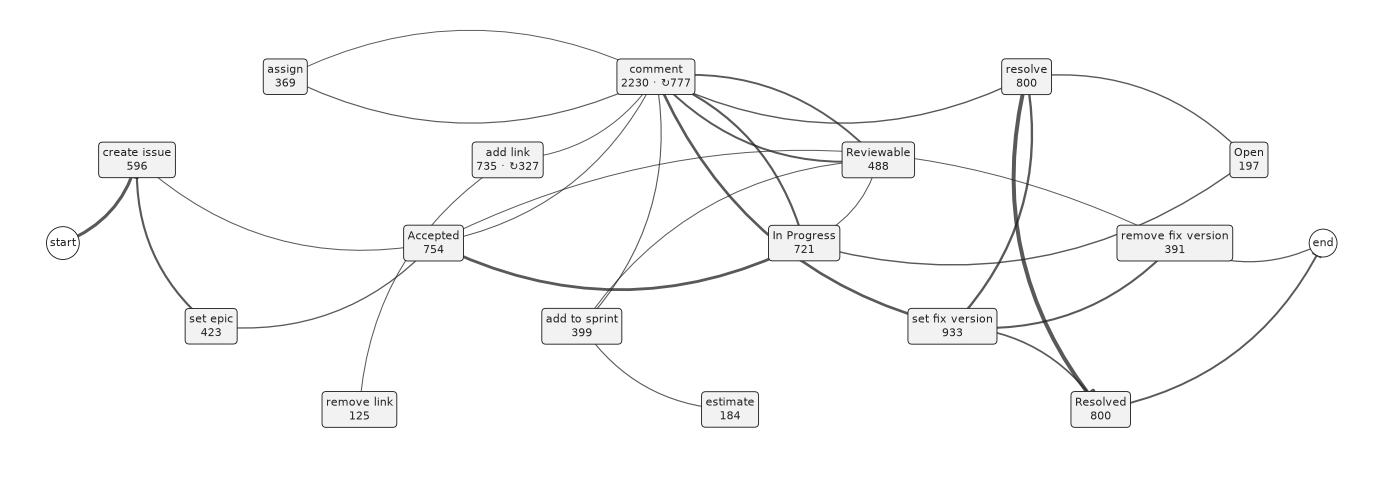

In [11]:
L = load_ocel(SAMPLE)
TITLE = L.issues["title"].fillna("").str.strip('"').to_dict()
net = mine(L, "release:414", e3=e3_llm.as_evidence(e3_llm.load("MESOS-release:414")))
tasks = net.tasks.task

nodes, arcs = views.ocdfg(L, tasks)
print(f"Directly-follows graph of the {len(tasks)} tasks: {len(nodes) - 2} activities, "
      f"{len(arcs)} arcs, {nodes.frequency.drop(['start', 'end']).sum()} events")
views.plot_dfg(nodes, arcs, max_arcs=30);

The 30 most frequent arcs already form a dense graph. They describe the review workflow and the
bookkeeping around it, e.g., comments, sprint assignments, and fix versions. The project network
of the same release relates individual tasks:

In [12]:
types = pd.Series([e["type"] for e in net.edges.values()]).value_counts()
hidden = sum(e["hidden"] for e in net.edges.values())
groups = sorted(nx.weakly_connected_components(nx.DiGraph(list(net.edges))), key=len, reverse=True)
print(f"{len(tasks)} tasks, {int(net.tasks.alpha.isna().sum())} without a recorded start")
print(f"{len(net.edges)} precedences ({', '.join(f'{n} {t}' for t, n in types.items())}), "
      f"{hidden} hidden (stated only in text)")
print(f"{sum(map(len, groups))} tasks in {len(groups)} groups of connected tasks, "
      f"largest groups: {[len(g) for g in groups[:5]]}")

596 tasks, 50 without a recorded start
83 precedences (71 FF, 12 FS), 15 hidden (stated only in text)
102 tasks in 23 groups of connected tasks, largest groups: [42, 12, 4, 4, 3]


Most tasks of the release are independent of each other. The precedences form many small
groups and a few larger ones. The PERT chart of the group around GPU support shows how its
tasks depended on each other. The realized slack refers to the last finish in the group.

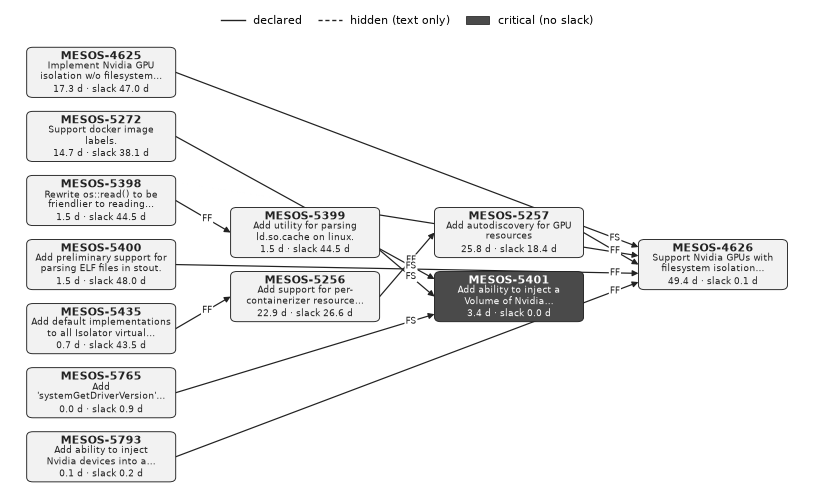

In [13]:
gpu = sorted(next(g for g in groups if "MESOS-4626" in g))
views.plot_pert(net, tasks=gpu, titles=TITLE);

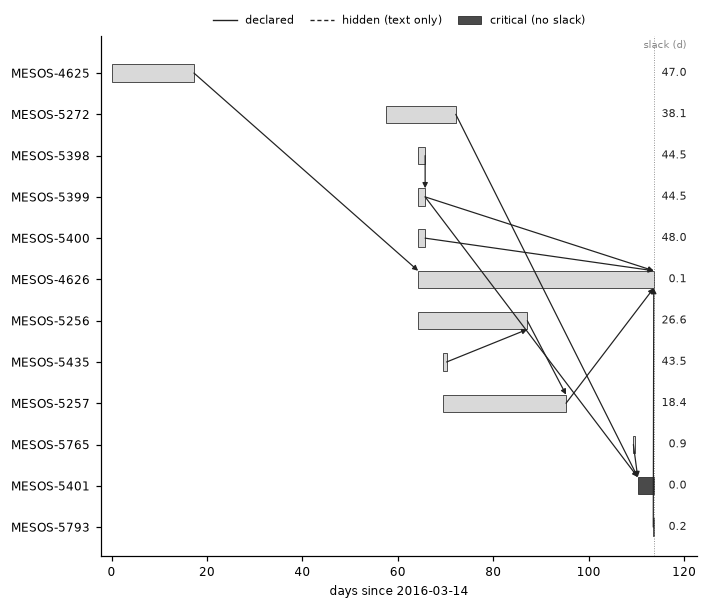

In [14]:
views.plot_gantt(net, tasks=gpu);

Hidden dependencies of the release, with the sentence that states them:

In [15]:
table = views.precedence_table(net)
table[table.evidence == "text only (hidden)"][["predecessor", "successor", "type", "quote"]]

,predecessor,successor,type,quote
68,MESOS-1865,MESOS-4680,FF,This one fixed in MESOS-1865
69,MESOS-3782,MESOS-3783,FS,"Therefore, I would suggest to do this at last, or at least after the majority of code change is ..."
70,MESOS-5271,MESOS-3781,FF,Let me work on adding multiple name support to flags and then you can base your deprecation patc...
71,MESOS-4090,MESOS-5233,FS,"After MESOS-4090, all native code is move out of {{src/python/native}}."
72,MESOS-4689,MESOS-5060,FF,There is currently a design doc in progress which will be introducing a versioned operator HTTP ...
73,MESOS-4759,MESOS-5117,FF,"In MESOS-4641, we have made the container created by Mesos can join CNI network by introducing {..."
74,MESOS-4951,MESOS-4933,FF,"May depend on MESOS-4951 (pass authn realm to libprocess), similar to MESOS-4956 (/files authn)."
75,MESOS-5404,MESOS-5170,FF,"As we need to be able to authorize `Tasks` (e.g., for deciding whether to include them in the /s..."
76,MESOS-5271,MESOS-5370,FF,MESOS-5271 adds support for a flag name to have an alias.
77,MESOS-5265,MESOS-5641,FS,"The mesos-execute was fixed in MESOS-5265 , the document should be updated to reflect how to use..."


Step 5 also estimates a duration distribution for each task from earlier tasks of the same
issue type, component, and story points (reference classes with the Kaplan–Meier estimator).
These estimates are not validated in the paper. For the GPU group:

In [16]:
net.tasks.set_index("task").loc[gpu, ["d_obs", "p10", "p50", "p90"]].round(1).assign(
    title=lambda t: t.index.map(TITLE))

,d_obs,p10,p50,p90,title
task,,,,,
MESOS-4625,17.3,0.3,8.9,246.2,Implement Nvidia GPU isolation w/o filesystem isolation enabled.
MESOS-4626,49.4,0.3,8.9,246.2,Support Nvidia GPUs with filesystem isolation enabled in mesos containerizer.
MESOS-5256,22.9,0.3,8.9,246.2,Add support for per-containerizer resource enumeration
MESOS-5257,25.8,0.3,8.9,246.2,Add autodiscovery for GPU resources
MESOS-5272,14.7,0.3,8.9,246.2,Support docker image labels.
MESOS-5398,1.5,0.9,19.0,548.8,Rewrite os::read() to be friendlier to reading binary files
MESOS-5399,1.5,0.9,19.0,548.8,Add utility for parsing ld.so.cache on linux.
MESOS-5400,1.5,0.9,19.0,548.8,Add preliminary support for parsing ELF files in stout.
MESOS-5401,3.4,0.9,19.0,548.8,Add ability to inject a Volume of Nvidia libraries/binaries into a docker-image container in mes...


## 5 What project mining adds

Both views come from the same OCEL, but they answer different questions:

| Question | Object-centric process mining | Object-centric project mining |
|---|---|---|
| Through which steps does work on issues go? | directly-follows graph of activities | – |
| Which task had to wait for which? | not answerable: activities abstract from objects (Proposition 1) | precedence between individual tasks |
| Does a dependency constrain starts or finishes? | – | typed precedence: FS, SS, FF, SF |
| Which tasks determined the end, and how much could a task be delayed? | – | critical path and slack |
| Which dependencies are stated only in text? | – | hidden dependencies, each with a verbatim quote |
| Which declared dependencies were withdrawn? | frequency of the activity *remove link* | removed links count as negative evidence |

Process mining describes the recurring workflow, and project mining describes the dependencies
of one release. The two views complement each other.